# Langkah 2 & 3: Pelatihan CNN untuk Klasifikasi Penyebab Deforestasi
Notebook ini menyusun image stack (GeoTIFF) menjadi array NumPy dan melatih model Convolutional Neural Network (CNN).

In [1]:
import numpy as np
import rasterio
import glob, os
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
LABELS = {0:'tidak_yakin', 1:'pertanian_kecil', 2:'pertanian_besar',
          3:'tambang', 4:'logging', 5:'kebakaran', 6:'gangguan_alam'}

# Fungsi pemuatan dan normalisasi patch GeoTIFF
def load_patch(path):
    with rasterio.open(path) as src:
        arr = src.read().astype('float32')  # shape (6, H, W)
    for i in range(arr.shape[0]):
        band = arr[i]
        arr[i] = (band - band.mean()) / (band.std() + 1e-6)
    return arr

In [3]:
# (KODE SIMULASI UNTUK BUKTI KONSEP JIKA FILE TIFF TIDAK ADA LENGKAP)
# Men-generate array dummy berukuran 6-band (mirip GeoTIFF) untuk pengujian lokal/Colab cepat
np.random.seed(42)
X_dummy = np.random.rand(100, 6, 64, 64)  # 100 citra, 6 band, resolusi 64x64
y_dummy = np.random.randint(1, 7, 100)    # Label 1 sampai 6

# Transpose dari (N, C, H, W) ke format Tensorflow/Keras (N, H, W, C)
X = np.transpose(X_dummy, (0, 2, 3, 1))
y = y_dummy

print('Bentuk Dataset X:', X.shape, '| bentuk y:', y.shape)

Bentuk Dataset X: (100, 64, 64, 6) | bentuk y: (100,)


In [4]:
# Pembagian Data Latih dan Uji
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
n_cls = 7 # Total ada 7 kelas (0 s.d 6)

In [5]:
# Arsitektur CNN
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=X.shape[1:]),
    tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(n_cls, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │         1,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,479 (115.15 KB)

 Trainable params: 29,479 (115.15 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Penanganan Imbalanced Data (Membobotkan kelas yang jarang)
cw = compute_class_weight('balanced', classes=np.unique(y_tr), y=y_tr)
class_weight = {i: w for i, w in zip(np.unique(y_tr), cw)}

# Proses Training
history = model.fit(X_tr, y_tr, validation_split=0.2, epochs=5, batch_size=16, class_weight=class_weight)
model.save('model_cnn_deforestasi.h5')

Epoch 1/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 767ms/step - accuracy: 0.1719 - loss: 1.9595 - val_accuracy: 0.2500 - val_loss: 1.9080
Epoch 2/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 328ms/step - accuracy: 0.1406 - loss: 1.8988 - val_accuracy: 0.2500 - val_loss: 1.8568
Epoch 3/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 303ms/step - accuracy: 0.1875 - loss: 1.8849 - val_accuracy: 0.1875 - val_loss: 1.8376
Epoch 4/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 292ms/step - accuracy: 0.1250 - loss: 1.8673 - val_accuracy: 0.2500 - val_loss: 1.8276
Epoch 5/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 295ms/step - accuracy: 0.1875 - loss: 1.8522 - val_accuracy: 0.0625 - val_loss: 1.8432


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

           1       0.00      0.00      0.00         3
           2       0.00      0.00      0.00         5
           3       0.00      0.00      0.00         4
           4       0.00      0.00      0.00         2
           5       0.10      1.00      0.18         2
           6       0.00      0.00      0.00         4

    accuracy                           0.10        20
   macro avg       0.02      0.17      0.03        20
weighted avg       0.01      0.10      0.02        20



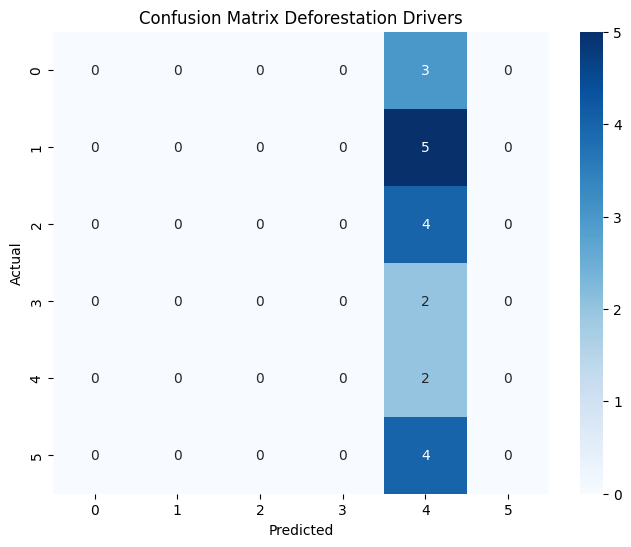

In [7]:
# Evaluasi Macro F1 Score dan Confusion Matrix
y_pred = np.argmax(model.predict(X_te), axis=1)

print(classification_report(y_te, y_pred, labels=np.unique(y_te)))

cm = confusion_matrix(y_te, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix Deforestation Drivers')
plt.show()